# Ансамблевая классификация дохода
Задание 4. Сравниваем бэггинг, случайный лес и AdaBoost на [UCI Adult](https://archive.ics.uci.edu/dataset/2/adult) (Barry Becker, Ronny Kohavi; CC BY 4.0).

Запустите ячейки сверху вниз в Google Colab. Файлы `adult.data` и `adult.test` загружаются автоматически, если их нет рядом с блокнотом. Каждый метод проверяем при **50, 60, 70, 80, 90 и 100 участниках**.

Обучение: все 32 561 записи `adult.data`. Проверка: все 16 281 записи `adult.test`. Это то же разделение, что в первом эксперименте задания 3. Класс 1 означает доход **>50K**, класс 0 — **≤50K**.

In [1]:
# Блокнот обучает ансамбли на Adult, считает метрики и сравнивает их с прошлым деревом.
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.feature_extraction import DictVectorizer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

COLUMNS = ["age", "workclass", "fnlwgt", "education", "education-num",
           "marital-status", "occupation", "relationship", "race", "sex",
           "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"]
TECHNIQUES = {"bagging": "Бэггинг", "random_forest": "Случайный лес", "boosting": "AdaBoost"}
METRICS = ["accuracy", "precision", "recall", "f1"]


def load_data(filename):
    # Вход: имя CSV Adult. Выход: таблица 14 признаков и класса income=0/1.
    path = Path(filename)
    if not path.exists():
        urlretrieve("https://archive.ics.uci.edu/ml/machine-learning-databases/adult/" + filename, path)
    data = pd.read_csv(path, names=COLUMNS, skipinitialspace=True, comment="|")
    data = data.replace("?", "Unknown")  # Сохраняем строки с неизвестными категориями.
    labels = data["income"].str.rstrip(".")
    if not labels.isin(["<=50K", ">50K"]).all():
        raise ValueError("Неожиданные метки дохода в файле.")
    data["income"] = (labels == ">50K").astype(int)
    return data


def quality(actual, predicted):
    # Вход: истинные и предсказанные классы 0/1. Выход: четыре метрики в долях.
    return {"accuracy": accuracy_score(actual, predicted),
            "precision": precision_score(actual, predicted, zero_division=0),
            "recall": recall_score(actual, predicted, zero_division=0),
            "f1": f1_score(actual, predicted, zero_division=0)}


train_data = load_data("adult.data")
test_data = load_data("adult.test")
print(f"Обучение: {len(train_data)}; тест: {len(test_data)}; scikit-learn: {sklearn.__version__}")
display(train_data.head())

Обучение: 32561; тест: 16281; scikit-learn: 1.9.1


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,0
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,0
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,0
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,0
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,0


## Программа классификации
Категории кодируются отдельными признаками 0/1 (one-hot); числовые значения сохраняются. Кодировщик обучается **только на обучающей таблице**. Неизвестная в обучении категория при проверке не создаёт новый столбец.

- **Бэггинг:** деревья обучаются на случайных выборках с возвращением. Каждый участник голосует за один класс; побеждает большинство, при равенстве — класс 0. Это схема со слайдов 40–41.
- **Случайный лес:** дополнительно при поиске каждого разбиения рассматривается случайное подмножество признаков. Здесь также используется голосование по классам.
- **AdaBoost:** деревья обучаются последовательно; веса ошибочно распознанных записей увеличиваются. Итог зависит от взвешенных голосов участников. В библиотечной реализации веса передаются непосредственно при обучении дерева; в примере презентации по весам повторно выбираются строки.

Параметры `max_depth`, `min_leaf`, `criterion` задают базовые деревья; `max_samples` — долю строк в bootstrap-выборке для бэггинга и леса; `max_features` — число признаков при разбиении в лесе; `learning_rate` — силу обновления весов AdaBoost. Для леса признаки выбираются **после one-hot-кодирования**.

Библиотека строит деревья и обучает ансамбли. Голосование большинства для бэггинга и леса выписано отдельно: стандартный `predict` этих классов усредняет вероятности, что может дать другой результат.

In [2]:
def make_ensemble(technique, n_estimators, max_depth=3, min_leaf=30,
                  criterion="entropy", max_samples=1.0, max_features="sqrt",
                  learning_rate=0.5, random_state=42):
    # Вход: техника, число участников и описанные выше параметры метода.
    # Выход: необученный ансамбль; неизвестная техника вызывает ошибку.
    tree = DecisionTreeClassifier(criterion=criterion, max_depth=max_depth,
                                  min_samples_leaf=min_leaf, random_state=random_state)
    if technique == "bagging":
        return BaggingClassifier(estimator=tree, n_estimators=n_estimators,
                                 max_samples=max_samples, bootstrap=True,
                                 random_state=random_state, n_jobs=1)
    if technique == "random_forest":
        return RandomForestClassifier(n_estimators=n_estimators, criterion=criterion,
                                      max_depth=max_depth, min_samples_leaf=min_leaf,
                                      max_features=max_features, max_samples=max_samples,
                                      bootstrap=True, random_state=random_state, n_jobs=1)
    if technique == "boosting":
        return AdaBoostClassifier(estimator=tree, n_estimators=n_estimators,
                                  learning_rate=learning_rate, random_state=random_state)
    raise ValueError("Техника: bagging, random_forest или boosting.")


def ensemble_predict(model, X, technique):
    # Вход: обученный ансамбль, закодированные признаки, техника. Выход: классы 0/1.
    if technique == "boosting":
        return model.predict(X)  # AdaBoost использует взвешенное голосование.
    votes = np.zeros(X.shape[0], dtype=int)
    for i, tree in enumerate(model.estimators_):
        features = model.estimators_features_[i] if technique == "bagging" else slice(None)
        votes += tree.predict(X[:, features]).astype(int)
    return (votes > len(model.estimators_) / 2).astype(int)


def classify_ensemble(train, test, technique="bagging", n_estimators=50, **params):
    # Вход: обучающая/тестовая таблицы с income=0/1, техника, размер и параметры.
    # Выход: модель, кодировщик и словарь метрик с фактическим числом участников.
    encoder = DictVectorizer(sparse=False, dtype=np.float32)
    X_train = encoder.fit_transform(train.drop(columns="income").to_dict("records"))
    X_test = encoder.transform(test.drop(columns="income").to_dict("records"))
    model = make_ensemble(technique, n_estimators, **params)
    model.fit(X_train, train["income"].to_numpy())
    predicted = ensemble_predict(model, X_test, technique)
    result = quality(test["income"].to_numpy(), predicted)
    result["Обучено"] = len(model.estimators_)
    return model, encoder, result

## Дерево из предыдущего задания
Для линии сравнения берём **сохранённые результаты собственного дерева Information gain** из задания 3: глубина 3, минимум 30 записей в листе, обучение на `adult.data`, тест на `adult.test`.

Точные значения ниже вычисляются из его проверенной матрицы ошибок: TP = 1951, TN = 11803, FP = 632, FN = 1895. Это результаты прошлой модели, а не переобученное библиотечное дерево. Если заменить набор данных или разделение, нужно заново получить базовые метрики; прежняя линия сравнения к другим данным не относится.

In [3]:
# Базовые значения из задания 3 для неизменных исходных выборок Adult.
TP, TN, FP, FN = 1951, 11803, 632, 1895
baseline = {"accuracy": (TP + TN) / (TP + TN + FP + FN),
            "precision": TP / (TP + FP), "recall": TP / (TP + FN),
            "f1": 2 * TP / (2 * TP + FP + FN)}
display(pd.DataFrame([baseline], index=["Дерево Information gain"]).round(4))

,accuracy,precision,recall,f1
Дерево Information gain,0.8448,0.7553,0.5073,0.6069


## Эксперимент с количеством участников
Для всех трёх методов задаём одинаковые параметры базового дерева: `max_depth=3`, `min_leaf=30`, `criterion="entropy"` (Information gain). Для бэггинга и леса размер каждой выборки с возвращением равен размеру обучения (`max_samples=1.0`). В лесе `max_features="sqrt"`; у AdaBoost `learning_rate=0.5`.

Внутри каждой техники меняется **только количество участников**. Фиксируем `random_state=42`. Тестовая выборка во всех 18 запусках одна и та же; при обучении и кодировании её метки не используются. AdaBoost может завершиться раньше заданного числа итераций, поэтому выводим также фактическое число обученных деревьев.

Accuracy — доля всех правильных ответов. Precision — доля верных среди предсказаний >50K. Recall — доля найденных записей класса >50K. F1 — гармоническое среднее precision и recall.

In [4]:
N_ESTIMATORS = list(range(50, 101, 10))
PARAMS = dict(max_depth=3, min_leaf=30, criterion="entropy",
              max_samples=1.0, max_features="sqrt", learning_rate=0.5, random_state=42)

results = []
for technique, label in TECHNIQUES.items():
    for n in N_ESTIMATORS:
        model, encoder, metrics = classify_ensemble(train_data, test_data, technique, n, **PARAMS)
        results.append({"Метод": label, "Участников": n, **metrics})
    print(f"{label}: готово")
results = pd.DataFrame(results)
display(results.round(4))

Бэггинг: готово
Случайный лес: готово
AdaBoost: готово


,Метод,Участников,accuracy,precision,recall,f1,Обучено
0,Бэггинг,50,0.8448,0.7553,0.5073,0.6069,50
1,Бэггинг,60,0.8448,0.7553,0.5073,0.6069,60
2,Бэггинг,70,0.8448,0.7553,0.5073,0.6069,70
3,Бэггинг,80,0.8448,0.7553,0.5073,0.6069,80
4,Бэггинг,90,0.8448,0.7553,0.5073,0.6069,90
5,Бэггинг,100,0.8448,0.7553,0.5073,0.6069,100
6,Случайный лес,50,0.7754,1.0000,0.0494,0.0942,50
7,Случайный лес,60,0.7785,1.0000,0.0624,0.1175,60
8,Случайный лес,70,0.7718,1.0000,0.0341,0.0659,70
9,Случайный лес,80,0.7730,1.0000,0.0390,0.0751,80


## Зависимость качества от размера ансамбля
Сплошные линии показывают ансамбли, пунктир — одиночное дерево из задания 3. Все шкалы начинаются с нуля; над 100% оставлен небольшой отступ, чтобы точки не обрезались. Линия бэггинга может совпасть с пунктиром базового дерева.

Разница с одиночным деревом, п.п.:


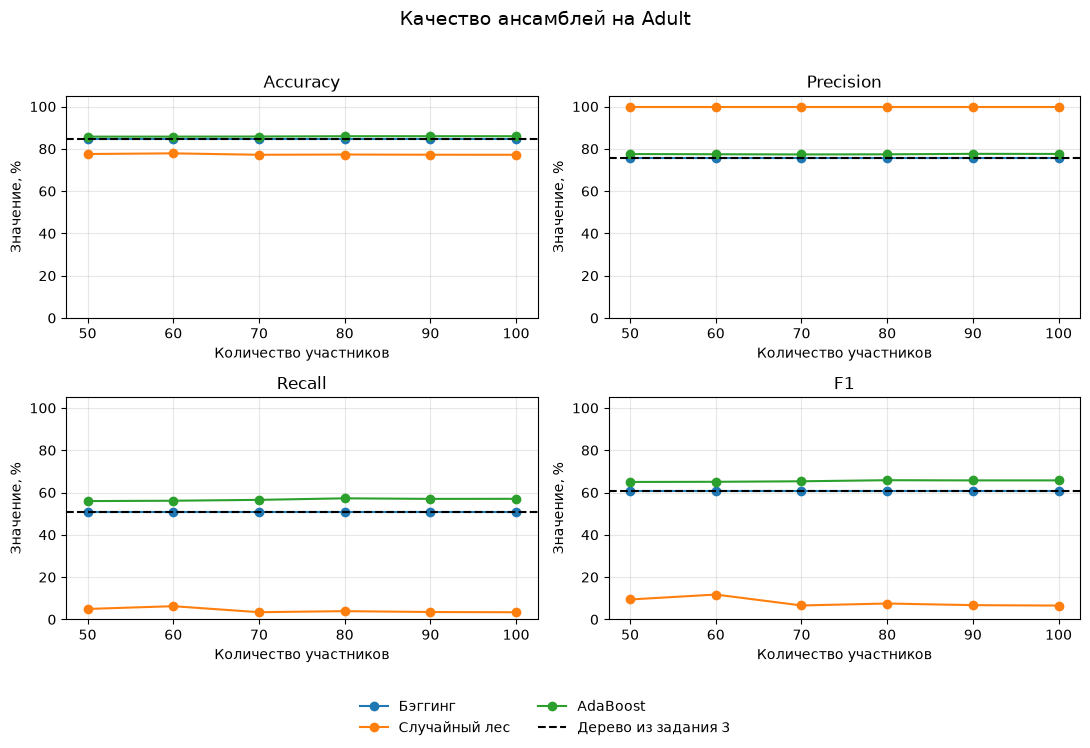

,Метод,Участников,accuracy,precision,recall,f1
0,Бэггинг,50,0.00,0.00,0.00,0.00
1,Бэггинг,60,0.00,0.00,0.00,0.00
2,Бэггинг,70,0.00,0.00,0.00,0.00
3,Бэггинг,80,0.00,0.00,0.00,0.00
4,Бэггинг,90,0.00,0.00,0.00,0.00
5,Бэггинг,100,0.00,0.00,0.00,0.00
6,Случайный лес,50,-6.93,24.47,-45.79,-51.28
7,Случайный лес,60,-6.63,24.47,-44.49,-48.95
8,Случайный лес,70,-7.30,24.47,-47.32,-54.11
9,Случайный лес,80,-7.18,24.47,-46.83,-53.19


In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
for ax, metric in zip(axes.flat, METRICS):
    for label in TECHNIQUES.values():
        part = results[results["Метод"] == label]
        ax.plot(part["Участников"], part[metric] * 100, marker="o", label=label)
    ax.axhline(baseline[metric] * 100, color="black", linestyle="--", label="Дерево из задания 3")
    ax.set(title=metric.upper() if metric == "f1" else metric.capitalize(),
           xlabel="Количество участников", ylabel="Значение, %", xticks=N_ESTIMATORS, yticks=range(0, 101, 20), ylim=(0, 105))
    ax.grid(alpha=0.3)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False)
fig.suptitle("Качество ансамблей на Adult", fontsize=14)
fig.tight_layout(rect=(0, 0.09, 1, 0.96))
Path("figures").mkdir(exist_ok=True)
fig.savefig("figures/ensemble_metrics.png", dpi=220, bbox_inches="tight")
plt.show()

# Изменение метрик относительно прошлого дерева в процентных пунктах.
difference = results[["Метод", "Участников"]].copy()
for metric in METRICS:
    difference[metric] = (results[metric] - baseline[metric]) * 100
print("Разница с одиночным деревом, п.п.:")
display(difference.round(2))

## Как понимать сравнение
Большее количество участников не гарантирует роста каждой метрики. Результат зависит от качества базовых деревьев и того, насколько похожи их ошибки. Здесь глубина каждого дерева ограничена тремя разбиениями; много слабых похожих деревьев могут сохранить общие ошибки.

Оценивайте precision вместе с recall: высокий доход встречается реже, и модель может показывать высокую accuracy, пропуская много записей класса >50K. Различия относятся к указанным настройкам и одному `random_state`; максимум на тестовом графике не доказывает, что этот метод или размер ансамбля всегда лучше.